# Butterfly Image Classification — Simple Neural Network

**Dataset:** [Butterfly Image Classification](https://www.kaggle.com/datasets/phucthaiv02/butterfly-image-classification) (Kaggle, phucthaiv02)


## 1. Imports

In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf

try:
    tf.config.set_visible_devices([], "GPU")
except RuntimeError:
    pass

from tensorflow.keras import layers, models, utils

print("TensorFlow version:", tf.__version__)
print("Using GPU:", bool(tf.config.list_logical_devices("GPU")))

TensorFlow version: 2.21.0
Using GPU: True


## 2. Configuration

In [ ]:
DATASET_DIR = "/home/farroyo/butterfly"  # dataset root
IMAGES_DIR  = os.path.join(DATASET_DIR, "train")  # folder containing .jpg files
CSV_PATH    = os.path.join(DATASET_DIR, "Training_set.csv")

IMG_SIZE      = (64, 64)   # resized image dimensions (kept small since no CNN is used)
RANDOM_STATE  = 42
BATCH_SIZE    = 8
EPOCHS        = 30

## 3. Load Labels

In [ ]:
df = pd.read_csv(CSV_PATH)
print("Sample of label file:")
display(df.head())
print(f"\nTotal images listed: {len(df)}")
print(f"Number of classes: {df['label'].nunique()}")

Sample of label file:


,filename,label
0,Image_1.jpg,SOUTHERN DOGFACE
1,Image_2.jpg,ADONIS
2,Image_3.jpg,BROWN SIPROETA
3,Image_4.jpg,MONARCH
4,Image_5.jpg,GREEN CELLED CATTLEHEART



Total images listed: 6499
Number of classes: 75


## 4. Preview a Few Sample Images

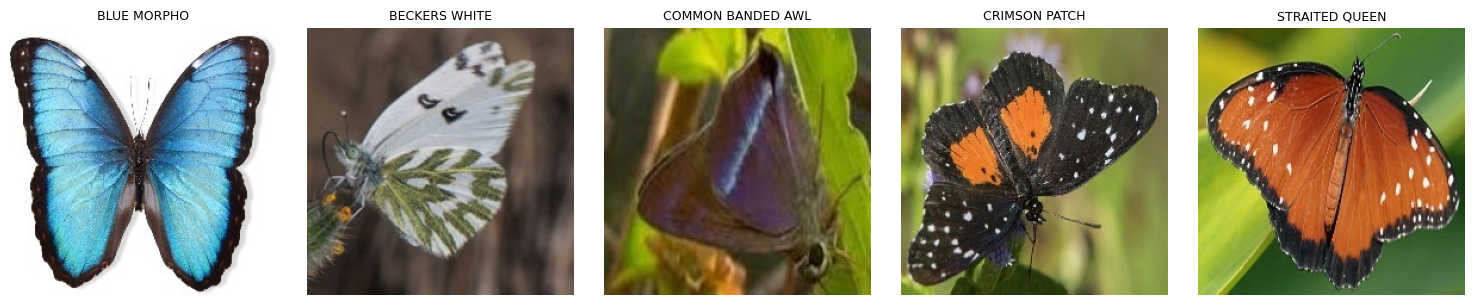

In [ ]:
available_df = df[df["filename"].map(lambda filename: os.path.isfile(os.path.join(IMAGES_DIR, filename)))]
if len(available_df) < 5:
    raise ValueError("Fewer than 5 training images are available for preview.")

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
sample_df = available_df.sample(5, random_state=RANDOM_STATE)
for ax, (_, row) in zip(axes, sample_df.iterrows()):
    img = Image.open(os.path.join(IMAGES_DIR, row["filename"]))
    ax.imshow(img)
    ax.set_title(row["label"], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Load & Preprocess Images into Arrays

Each image is resized, converted to a NumPy array, and pixel values are normalized to `[0, 1]`.

In [ ]:
def load_images(dataframe, images_dir, img_size):
    images = []
    labels = []
    for _, row in dataframe.iterrows():
        img_path = os.path.join(images_dir, row["filename"])
        try:
            img = Image.open(img_path).convert("RGB").resize(img_size)
            images.append(np.array(img))
            labels.append(row["label"])
        except (FileNotFoundError, OSError) as e:
            print(f"Skipping {img_path}: {e}")
    return np.array(images), np.array(labels)

print("Loading and resizing images (this may take a few minutes)...")
X, y_raw = load_images(df, IMAGES_DIR, IMG_SIZE)

# Normalize pixel values to [0, 1]
X = X.astype("float32") / 255.0

print(f"Image array shape: {X.shape}")

Loading and resizing images (this may take a few minutes)...
Skipping /home/farroyo/butterfly/train/Image_6.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_6.jpg'
Skipping /home/farroyo/butterfly/train/Image_7.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_7.jpg'
Skipping /home/farroyo/butterfly/train/Image_8.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_8.jpg'
Skipping /home/farroyo/butterfly/train/Image_9.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_9.jpg'
Skipping /home/farroyo/butterfly/train/Image_59.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_59.jpg'
Skipping /home/farroyo/butterfly/train/Image_60.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_60.jpg'
Skipping /home/farroyo/butterfly/train/Image_61.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_61.jpg'
Sk

Skipping /home/farroyo/butterfly/train/Image_585.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_585.jpg'
Skipping /home/farroyo/butterfly/train/Image_586.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_586.jpg'
Skipping /home/farroyo/butterfly/train/Image_587.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_587.jpg'
Skipping /home/farroyo/butterfly/train/Image_588.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_588.jpg'
Skipping /home/farroyo/butterfly/train/Image_589.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_589.jpg'
Skipping /home/farroyo/butterfly/train/Image_590.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_590.jpg'
Skipping /home/farroyo/butterfly/train/Image_591.jpg: [Errno 2] No such file or directory: '/home/farroyo/butterfly/train/Image_591.jpg'
Skipping /home/farroyo/butterfly/train/Im

## 6. Encode Labels

String species names are converted to integers, then one-hot encoded for the softmax output.

In [ ]:
label_encoder = LabelEncoder()
y_int = label_encoder.fit_transform(y_raw)
y_onehot = utils.to_categorical(y_int)
NUM_CLASSES = len(label_encoder.classes_)

print(f"Encoded {NUM_CLASSES} classes")
print(f"y_int shape   : {y_int.shape}")
print(f"y_onehot shape: {y_onehot.shape}")

class_counts = df['label'].value_counts().sort_values(ascending=False)

print(f"Total classes: {len(class_counts)}")
print(f"Average images per class: {class_counts.mean():.2f}")
print()

largest_class = class_counts.idxmax()
largest_count = class_counts.max()
smallest_class = class_counts.idxmin()
smallest_count = class_counts.min()

print(f"Largest class : '{largest_class}' with {largest_count} images")
print(f"Smallest class: '{smallest_class}' with {smallest_count} images")
print()

print("Images per class (all 75 classes):")
with pd.option_context('display.max_rows', None):
    display(class_counts)

Encoded 75 classes
y_int shape   : (5384,)
y_onehot shape: (5384, 75)
Total classes: 75
Average images per class: 86.65

Largest class : 'MOURNING CLOAK' with 131 images
Smallest class: 'WOOD SATYR' with 71 images

Images per class (all 75 classes):


label
MOURNING CLOAK               131
SLEEPY ORANGE                107
ATALA                        100
BROWN SIPROETA                99
BANDED ORANGE HELICONIAN      97
CRECENT                       97
SCARCE SWALLOW                97
MILBERTS TORTOISESHELL        96
RED CRACKER                   96
ORANGE TIP                    96
CHECQUERED SKIPPER            95
EASTERN PINE ELFIN            95
IPHICLUS SISTER               95
DANAID EGGFLY                 94
COPPER TAIL                   94
GREAT JAY                     94
CLEOPATRA                     93
EASTERN COMA                  93
EASTERN DAPPLE WHITE          92
CLOUDED SULPHUR               92
PURPLISH COPPER               92
SOOTYWING                     90
PAPER KITE                    90
APPOLLO                       90
CABBAGE WHITE                 90
COMMON WOOD-NYMPH             90
MONARCH                       90
RED POSTMAN                   89
ADONIS                        88
GREEN CELLED CATTLEHEART      88
ORAN

## 7. Train / Validation / Test Split (70% / 15% / 15%)

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_onehot, test_size=0.30, random_state=RANDOM_STATE, stratify=y_int
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE,
    stratify=np.argmax(y_temp, axis=1)
)

print(f"Training samples  : {X_train.shape[0]}")
print(f"Validation samples: {X_val.shape[0]}")
print(f"Test samples      : {X_test.shape[0]}")

Training samples  : 3768
Validation samples: 808
Test samples      : 808


## 8. Build the Simple Neural Network

Each image is flattened into a 1D vector, then passed through Dense layers to a `softmax` output — **no `Conv2D` or `MaxPooling` layers**.

In [ ]:
tf.keras.backend.clear_session()

with tf.device("/CPU:0"):
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 75)             │        19,275 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,442,571 (24.58 MB)

 Trainable params: 6,442,571 (24.58 MB)

 Non-trainable params: 0 (0.00 B)

## 9. Compile the Model

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

## 10. Train the Model

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

Epoch 1/30
471/471 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.0170 - loss: 4.3437 - val_accuracy: 0.0347 - val_loss: 4.2420
Epoch 2/30
471/471 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.0374 - loss: 4.1897 - val_accuracy: 0.0582 - val_loss: 4.0353
Epoch 3/30
471/471 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.0565 - loss: 4.0173 - val_accuracy: 0.0681 - val_loss: 3.8219
Epoch 4/30
471/471 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.0701 - loss: 3.8536 - val_accuracy: 0.0953 - val_loss: 3.6449
Epoch 5/30
471/471 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.0836 - loss: 3.7246 - val_accuracy: 0.1312 - val_loss: 3.5680
Epoch 6/30
471/471 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.0921 - loss: 3.6198 - val_accuracy: 0.1300 - val_loss: 3.4734
Epoch 7/30
471/471 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.1144 - loss: 3.5109 - val_accuracy: 0.1275 - val_loss: 3.4760
Epoch 8/30
471/471 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - accuracy: 0.1319 - loss: 3.4288 - val

## 11. Evaluate on the Test Set

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss    : 2.7190
Test Accuracy: 0.2946


In [ ]:
test_metrics_df = pd.DataFrame({
    "Metric": ["Test Loss", "Test Accuracy"],
    "Result": [f"{test_loss:.4f}", f"{test_acc:.4f}"]
})

display(test_metrics_df)

,Metric,Result
0,Test Loss,2.7190
1,Test Accuracy,0.2946


In [ ]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

print("Classification Report:")
print(classification_report(
    y_true, y_pred, target_names=label_encoder.classes_, zero_division=0
))

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
Classification Report:
                           precision    recall  f1-score   support

                   ADONIS       0.58      0.64      0.61        11
AFRICAN GIANT SWALLOWTAIL       1.00      0.40      0.57        10
           AMERICAN SNOOT       0.00      0.00      0.00         9
                    AN 88       0.56      0.42      0.48        12
                  APPOLLO       0.67      0.18      0.29        11
                    ATALA       0.29      0.42      0.34        12
 BANDED ORANGE HELICONIAN       0.00      0.00      0.00        11
           BANDED PEACOCK       0.57      0.36      0.44        11
            BECKERS WHITE       0.00      0.00      0.00        11
         BLACK HAIRSTREAK       0.00      0.00      0.00        11
              BLUE MORPHO       0.67      0.20      0.31        10
        BLUE SPOTTED CROW       0.20      0.10      0.13        10
           BROWN SIPROETA       0.54      0.58      0.56        1

In [ ]:
report_dict = classification_report(
    y_true, y_pred, target_names=label_encoder.classes_, zero_division=0, output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()
report_df = report_df.drop(index=["accuracy"], errors="ignore")  # keep only per-class + avg rows
report_df = report_df.rename(columns={
    "precision": "Precision", "recall": "Recall", "f1-score": "F1-Score", "support": "Support"
})
report_df.index.name = "Class"
report_df = report_df.round(4)
report_df["Support"] = report_df["Support"].astype(int)

display(report_df)

,Precision,Recall,F1-Score,Support
Class,,,,
ADONIS,0.5833,0.6364,0.6087,11
AFRICAN GIANT SWALLOWTAIL,1.0000,0.4000,0.5714,10
AMERICAN SNOOT,0.0000,0.0000,0.0000,9
AN 88,0.5556,0.4167,0.4762,12
APPOLLO,0.6667,0.1818,0.2857,11
...,...,...,...,...
WOOD SATYR,0.4286,0.3333,0.3750,9
YELLOW SWALLOW TAIL,0.8333,0.5000,0.6250,10
ZEBRA LONG WING,0.5000,0.1111,0.1818,9


## 12. Plot Training History

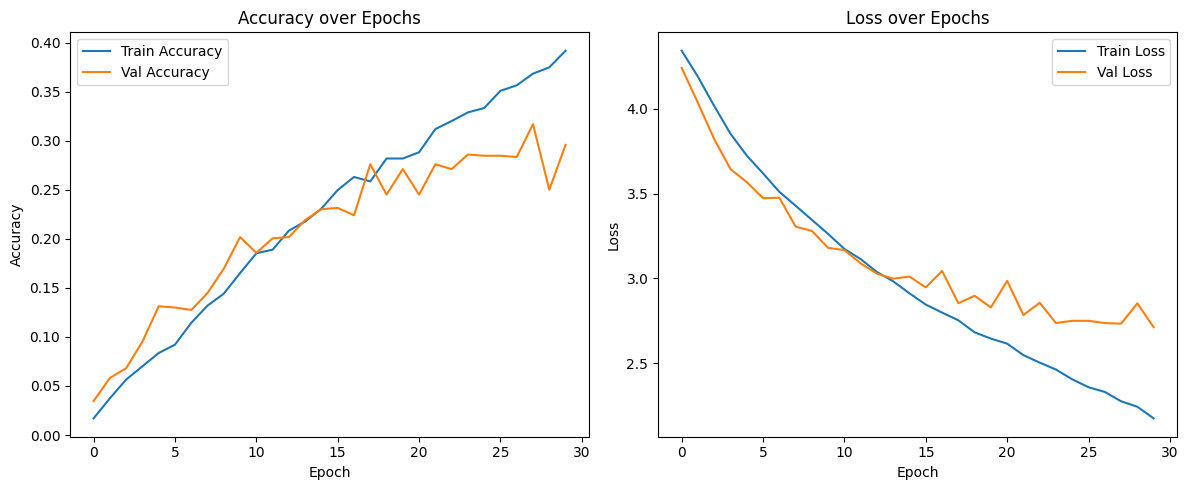

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("Accuracy over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Val Loss")
axes[1].set_title("Loss over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_history.png", dpi=150)
plt.show()

## 13. Confusion Matrix

With 75 classes the matrix is large, so it's saved as an image for closer inspection in your report.

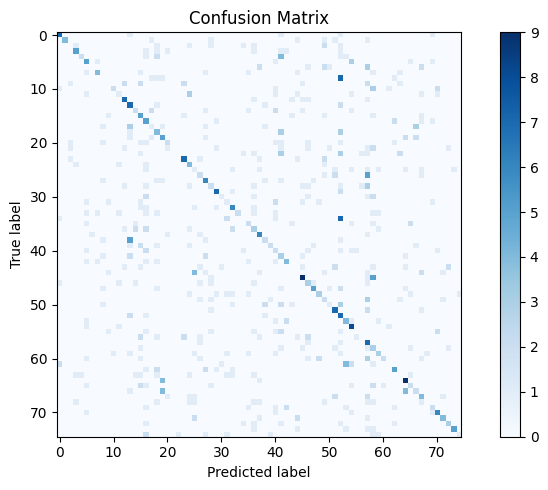

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar()
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

## 14. Resolution Experiments

To see how input resolution affects the simple (no-CNN) ANN, the same architecture is retrained from scratch at three input sizes:

- **Experiment 1** — 32 × 32 × 3
- **Experiment 2** — 64 × 64 × 3
- **Experiment 3** — 128 × 128 × 3

Each experiment reloads the images at that resolution, re-splits train/val/test (70/15/15, same random state), builds a fresh model with the same layer sizes (Dense 512 → Dropout 0.3 → Dense 256 → Dropout 0.3 → softmax), and trains with the same early-stopping rule.

In [ ]:
import gc
import time

class ImageSequence(utils.Sequence):
    def __init__(self, dataframe, images_dir, img_size, label_encoder, batch_size=4, shuffle=False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.images_dir = images_dir
        self.img_size = img_size
        self.label_encoder = label_encoder
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.dataframe))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.dataframe) / self.batch_size))

    def __getitem__(self, batch_index):
        batch_indices = self.indices[
            batch_index * self.batch_size:(batch_index + 1) * self.batch_size
        ]
        batch = self.dataframe.iloc[batch_indices]
        images = []
        labels = []
        for _, row in batch.iterrows():
            image_path = os.path.join(self.images_dir, row["filename"])
            image = Image.open(image_path).convert("RGB").resize(self.img_size)
            images.append(np.asarray(image, dtype="float32") / 255.0)
            labels.append(self.label_encoder.transform([row["label"]])[0])
        return np.asarray(images, dtype="float32"), utils.to_categorical(
            labels, num_classes=len(self.label_encoder.classes_)
        )

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


def run_experiment(img_size, dataframe, images_dir, epochs=EPOCHS, batch_size=4, random_state=RANDOM_STATE):
    """Train one resolution experiment without materializing the full image dataset."""
    tf.keras.backend.clear_session()
    gc.collect()

    available = dataframe[dataframe["filename"].map(
        lambda filename: os.path.isfile(os.path.join(images_dir, filename))
    )].copy()
    le_res = LabelEncoder()
    le_res.fit(available["label"])

    train_df, temp_df = train_test_split(
        available, test_size=0.30, random_state=random_state,
        stratify=available["label"]
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, random_state=random_state,
        stratify=temp_df["label"]
    )

    train_sequence = ImageSequence(
        train_df, images_dir, img_size, le_res, batch_size=batch_size, shuffle=True
    )
    val_sequence = ImageSequence(
        val_df, images_dir, img_size, le_res, batch_size=batch_size
    )
    test_sequence = ImageSequence(
        test_df, images_dir, img_size, le_res, batch_size=batch_size
    )

    with tf.device("/CPU:0"):
        exp_model = models.Sequential([
            layers.Input(shape=(img_size[0], img_size[1], 3)),
            layers.Flatten(),
            layers.Dense(512, activation="relu"),
            layers.Dropout(0.3),
            layers.Dense(256, activation="relu"),
            layers.Dropout(0.3),
            layers.Dense(len(le_res.classes_), activation="softmax")
        ])
    exp_model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
        jit_compile=False
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )
    start_time = time.time()
    hist = exp_model.fit(
        train_sequence,
        validation_data=val_sequence,
        epochs=epochs,
        callbacks=[early_stop],
        verbose=0
    )
    train_time = time.time() - start_time
    _, test_acc_res = exp_model.evaluate(test_sequence, verbose=0)

    return {
        "Resolution": f"{img_size[0]} × {img_size[1]}",
        "Input Features": img_size[0] * img_size[1] * 3,
        "Parameters": exp_model.count_params(),
        "Training Accuracy": hist.history["accuracy"][-1],
        "Validation Accuracy": hist.history["val_accuracy"][-1],
        "Test Accuracy": test_acc_res,
        "Training Time": train_time,
    }

In [ ]:
resolutions = [(32, 32), (64, 64), (128, 128)]
experiment_results = []

for size in resolutions:
    print(f"=== Experiment: {size[0]} x {size[1]} x 3 ===")
    result = run_experiment(size, df, IMAGES_DIR)
    experiment_results.append(result)
    print(f"  Training Accuracy  : {result['Training Accuracy']:.4f}")
    print(f"  Validation Accuracy: {result['Validation Accuracy']:.4f}")
    print(f"  Test Accuracy      : {result['Test Accuracy']:.4f}")
    print(f"  Training Time      : {result['Training Time']/60:.2f} min")
    print()
    tf.keras.backend.clear_session()
    gc.collect()

=== Experiment: 32 x 32 x 3 ===


/home/farroyo/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1787921922.720932 2638868 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
W0000 00:00:1787921923.994169 2707357 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787921924.003585 2707358 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787921924.010768 2707355 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1787921924.020427 2707360 

  Training Accuracy  : 0.4379
  Validation Accuracy: 0.3205
  Test Accuracy      : 0.3428
  Training Time      : 6.83 min

=== Experiment: 64 x 64 x 3 ===


/home/farroyo/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/home/farroyo/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/home/farroyo/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`

  Training Accuracy  : 0.2872
  Validation Accuracy: 0.2710
  Test Accuracy      : 0.2871
  Training Time      : 12.21 min

=== Experiment: 128 x 128 x 3 ===


/home/farroyo/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/home/farroyo/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/home/farroyo/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`

  Training Accuracy  : 0.0900
  Validation Accuracy: 0.1126
  Test Accuracy      : 0.1238
  Training Time      : 13.70 min



### Summary

In [ ]:
experiments_df = pd.DataFrame(experiment_results)

display_df = experiments_df.copy()
display_df["Parameters"] = display_df["Parameters"].apply(lambda p: f"{p:,}")
for col in ["Training Accuracy", "Validation Accuracy", "Test Accuracy"]:
    display_df[col] = display_df[col].apply(lambda v: f"{v:.4f}")
display_df["Training Time"] = display_df["Training Time"].apply(lambda s: f"{s/60:.2f} min")

display_df = display_df[[
    "Resolution", "Input Features", "Parameters",
    "Training Accuracy", "Validation Accuracy", "Test Accuracy", "Training Time"
]]

display(display_df)

,Resolution,Input Features,Parameters,Training Accuracy,Validation Accuracy,Test Accuracy,Training Time
0,32 × 32,3072,"1,723,979",0.4379,0.3205,0.3428,6.83 min
1,64 × 64,12288,"6,442,571",0.2872,0.2710,0.2871,12.21 min
2,128 × 128,49152,"25,316,939",0.0900,0.1126,0.1238,13.70 min
